---
title: "3.4.c Riesgo por calor extremo"
short_title: "c. Riesgo"
subtitle: "Calor de superficie, densidad de población y vegetación por celda"
description: "Cruce de la temperatura de superficie con la población y la vegetación para identificar las zonas de Leticia más expuestas al calor."
keywords: [calor, riesgo, vulnerabilidad, mapa bivariado, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/34_calor/c_riesgo.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

El riesgo por calor combina **cuánto se calienta un lugar** con **cuánta gente vive allí y qué tan sensible es**.
Sin datos censales por manzana de edad e ingreso, la vulnerabilidad se aproxima con la población estimada, la
densidad construida y la falta de vegetación (ver [1.1](../../01_conceptos/11_marco_riesgo.md)).

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import espacial, exposicion, fuentes, riesgo, viz
from leticia.config import parametros

pc = parametros()["calor"]
malla = exposicion.malla_exposicion()
lst = espacial.temperatura_superficie(2024, pc["meses_landsat"], nubes_max=pc["nubes_max"])
malla["lst_c"] = espacial.estadistica_zonal(lst["lst"].rio.write_crs(4326), malla)
malla["ndvi"] = espacial.estadistica_zonal(lst["ndvi"].rio.write_crs(4326), malla)
con = malla[(malla.n_edif > 0) & malla.lst_c.notna()].copy()
con["lst_anomalia"] = con["lst_c"] - con["lst_c"].median()

## 1. Temperatura de superficie por celda

Entre la celda más caliente y la mediana urbana hay **9.5 °C**; el 10 % más caliente supera la mediana en 5.9 °C o más.

,lst_c,lst_anomalia,ndvi,n_edif,poblacion
id,,,,,
26698_5458,43.15,9.50,0.29,60,810.28
26697_5461,42.89,9.24,0.31,67,901.09
26699_5456,42.84,9.19,0.37,68,606.81
26699_5455,42.65,9.00,0.30,55,628.20
26701_5456,42.61,8.95,0.34,80,747.09
26698_5457,42.54,8.89,0.35,55,509.31
26698_5455,42.52,8.87,0.33,56,663.81
26697_5457,42.49,8.83,0.31,51,507.10
26698_5459,42.47,8.82,0.35,53,726.06


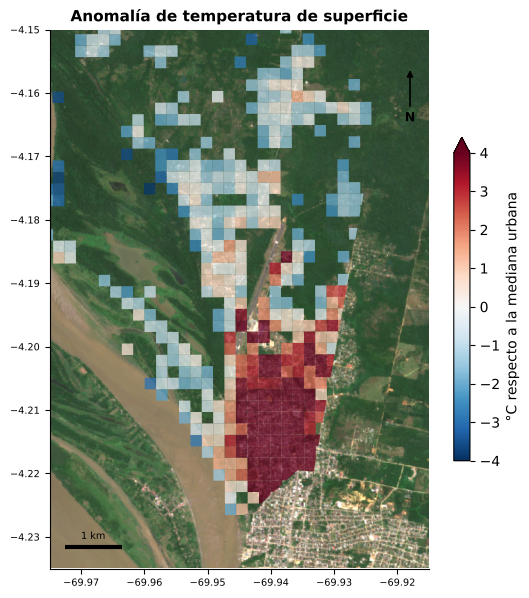

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 7))
viz.mapa_celdas(con, "lst_anomalia", ax=ax, cmap="RdBu_r", etiqueta="°C respecto a la mediana urbana", vmin=-4, vmax=4,
                titulo="Anomalía de temperatura de superficie")
top = con.nlargest(10, "lst_anomalia")[["lst_c", "lst_anomalia", "ndvi", "n_edif", "poblacion"]]
display(Markdown(f"Entre la celda más caliente y la mediana urbana hay **{con['lst_anomalia'].max():.1f} °C**; "
                 f"el 10 % más caliente supera la mediana en {con['lst_anomalia'].quantile(0.9):.1f} °C o más."))
display(top.round(2))

## 2. Calor y vulnerabilidad: mapa bivariado

Celdas con **calor alto y vulnerabilidad alta**: 114. con 40.666 personas estimadas (87 % de la población de la malla).

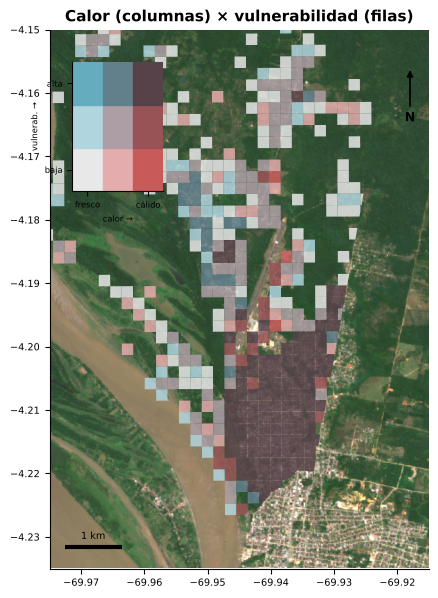

In [4]:
con["vulnerabilidad"] = riesgo.indice_vulnerabilidad(con, {
    "densidad_edificaciones": ("densidad_construida", False), "poblacion": ("poblacion", False), "baja_vegetacion": ("ndvi", True)})
t_cl = pd.qcut(con["lst_c"], 3, labels=[0, 1, 2]).astype(int)
v_cl = pd.qcut(con["vulnerabilidad"].rank(method="first"), 3, labels=[0, 1, 2]).astype(int)
paleta = np.array([["#e8e8e8", "#e4acac", "#c85a5a"], ["#b0d5df", "#ad9ea5", "#985356"], ["#64acbe", "#627f8c", "#574249"]])
con["color"] = [paleta[v, t] for t, v in zip(t_cl, v_cl)]
fig, ax = plt.subplots(figsize=(6.4, 7))
viz.fondo(ax)
con.to_crs(4326).plot(ax=ax, color=con["color"], alpha=0.85, linewidth=0, zorder=2)
viz.marco(ax, titulo="Calor (columnas) × vulnerabilidad (filas)")
ins = ax.inset_axes([0.06, 0.70, 0.24, 0.24])
for v in range(3):
    for t in range(3):
        ins.add_patch(plt.Rectangle((t, v), 1, 1, color=paleta[v, t]))
ins.set_xlim(0, 3); ins.set_ylim(0, 3)
ins.set_xticks([0.5, 2.5]); ins.set_xticklabels(["fresco", "cálido"], fontsize=6)
ins.set_yticks([0.5, 2.5]); ins.set_yticklabels(["baja", "alta"], fontsize=6)
ins.set_xlabel("calor →", fontsize=6); ins.set_ylabel("vulnerab. →", fontsize=6)
ins.grid(False)
alto = con[(t_cl == 2) & (v_cl == 2)]
display(Markdown(f"Celdas con **calor alto y vulnerabilidad alta**: {len(alto)}, con {alto['poblacion'].sum():,.0f} personas estimadas "
                 f"({100 * alto['poblacion'].sum() / con['poblacion'].sum():.0f} % de la población de la malla).".replace(",", ".")))

## 3. Clases de riesgo relativo

In [5]:
malla.loc[con.index, "vulnerabilidad"] = con["vulnerabilidad"]
malla["riesgo_calor"] = riesgo.matriz_riesgo(riesgo.clasificar(riesgo.normalizar(malla["lst_c"])),
                                            riesgo.clasificar(malla["vulnerabilidad"]))
display(malla[malla.n_edif > 0].groupby("riesgo_calor", observed=False)[["n_edif", "poblacion"]].sum().round(0))
malla[["lst_c", "ndvi", "riesgo_calor"]].to_csv(fuentes.ruta("riesgo_calor_celdas.csv"))

,n_edif,poblacion
riesgo_calor,,
Muy baja,154,226.00
Baja,507,922.00
Media,768,"2,170.00"
Alta,1809,"7,482.00"
Muy alta,3570,"35,706.00"


**Lectura.** Las celdas de calor alto y vulnerabilidad alta se concentran en los barrios densos y con poca
vegetación del centro y del oriente de la cabecera. Allí la arborización, los techos claros o ventilados y los
puntos de hidratación y sombra tienen mayor beneficio. El bosque y los humedales que aún rodean la ciudad
funcionan como refrigeración natural: perderlos por expansión urbana aumentaría el riesgo.